#  Patient Data Analysis — Heart Disease Dataset
### Author: Md Abrar Faiyaj
### Date:  8th May,2026
### Tools: Python, Pandas, SQLite, Matplotlib, Seaborn
**Goal:** Find patterns in patient data associated with heart disease risk.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

os.makedirs("../outputs", exist_ok=True)
print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
df = pd.read_csv("../data/heart.csv")
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


##  Step 1: Data Overview
Let's understand the structure and check for missing values.

In [3]:
print("Column Names:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
print("\nBasic Stats:")
df.describe()

Column Names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Basic Stats:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


##  Step 2: Data Cleaning
Rename columns for clarity and map binary values to readable labels.

In [4]:
df.rename(columns={
    'age': 'Age', 'sex': 'Sex', 'cp': 'ChestPainType',
    'trestbps': 'RestingBP', 'chol': 'Cholesterol',
    'fbs': 'FastingBS', 'restecg': 'RestingECG',
    'thalach': 'MaxHR', 'exang': 'ExerciseAngina',
    'oldpeak': 'Oldpeak', 'slope': 'Slope',
    'ca': 'NumVessels', 'thal': 'Thal', 'target': 'HeartDisease'
}, inplace=True)

df['Sex'] = df['Sex'].map({1: 'Male', 0: 'Female'})
df['HeartDisease'] = df['HeartDisease'].map({1: 'Disease', 0: 'No Disease'})
df['ExerciseAngina'] = df['ExerciseAngina'].map({1: 'Yes', 0: 'No'})
df.drop_duplicates(inplace=True)

print(f" Cleaned. Shape: {df.shape}")
df.head()

 Cleaned. Shape: (302, 14)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,Slope,NumVessels,Thal,HeartDisease
0,52,Male,0,125,212,0,1,168,No,1.0,2,2,3,No Disease
1,53,Male,0,140,203,1,0,155,Yes,3.1,0,0,3,No Disease
2,70,Male,0,145,174,0,1,125,Yes,2.6,0,0,3,No Disease
3,61,Male,0,148,203,0,1,161,No,0.0,2,1,3,No Disease
4,62,Female,0,138,294,1,1,106,No,1.9,1,3,2,No Disease


## Step 3: Store in SQLite & Run SQL Queries
We load the cleaned data into a SQLite database and extract insights using SQL.

In [5]:
conn = sqlite3.connect("../data/heart_disease.db")
df.to_sql("patients", conn, if_exists="replace", index=False)
print("Data saved to SQLite\n")

queries = {
    "Disease Distribution":
        "SELECT HeartDisease, COUNT(*) as Count FROM patients GROUP BY HeartDisease",

    "Average Age by Disease":
        "SELECT HeartDisease, ROUND(AVG(Age),1) as AvgAge FROM patients GROUP BY HeartDisease",

    "Gender vs Disease":
        "SELECT Sex, HeartDisease, COUNT(*) as Count FROM patients GROUP BY Sex, HeartDisease",

    "High Cholesterol Patients (>250)":
        "SELECT COUNT(*) as Count FROM patients WHERE Cholesterol > 250",

    "Avg Max Heart Rate by Disease":
        "SELECT HeartDisease, ROUND(AVG(MaxHR),1) as AvgMaxHR FROM patients GROUP BY HeartDisease",

    "Age Group Risk Analysis":
        """SELECT 
             CASE WHEN Age < 40 THEN 'Under 40'
                  WHEN Age BETWEEN 40 AND 55 THEN '40-55'
                  ELSE 'Over 55' END AS AgeGroup,
             HeartDisease, COUNT(*) as Count
           FROM patients
           GROUP BY AgeGroup, HeartDisease"""
}

for title, query in queries.items():
    print(f" {title}")
    print(pd.read_sql_query(query, conn))
    print()

conn.close()

Data saved to SQLite

 Disease Distribution
  HeartDisease  Count
0      Disease    164
1   No Disease    138

 Average Age by Disease
  HeartDisease  AvgAge
0      Disease    52.6
1   No Disease    56.6

 Gender vs Disease
      Sex HeartDisease  Count
0  Female      Disease     72
1  Female   No Disease     24
2    Male      Disease     92
3    Male   No Disease    114

 High Cholesterol Patients (>250)
   Count
0    126

 Avg Max Heart Rate by Disease
  HeartDisease  AvgMaxHR
0      Disease     158.4
1   No Disease     139.1

 Age Group Risk Analysis
   AgeGroup HeartDisease  Count
0     40-55      Disease     91
1     40-55   No Disease     45
2   Over 55      Disease     62
3   Over 55   No Disease     89
4  Under 40      Disease     11
5  Under 40   No Disease      4



## Step 4: Visualizations
Six charts to communicate key findings visually.

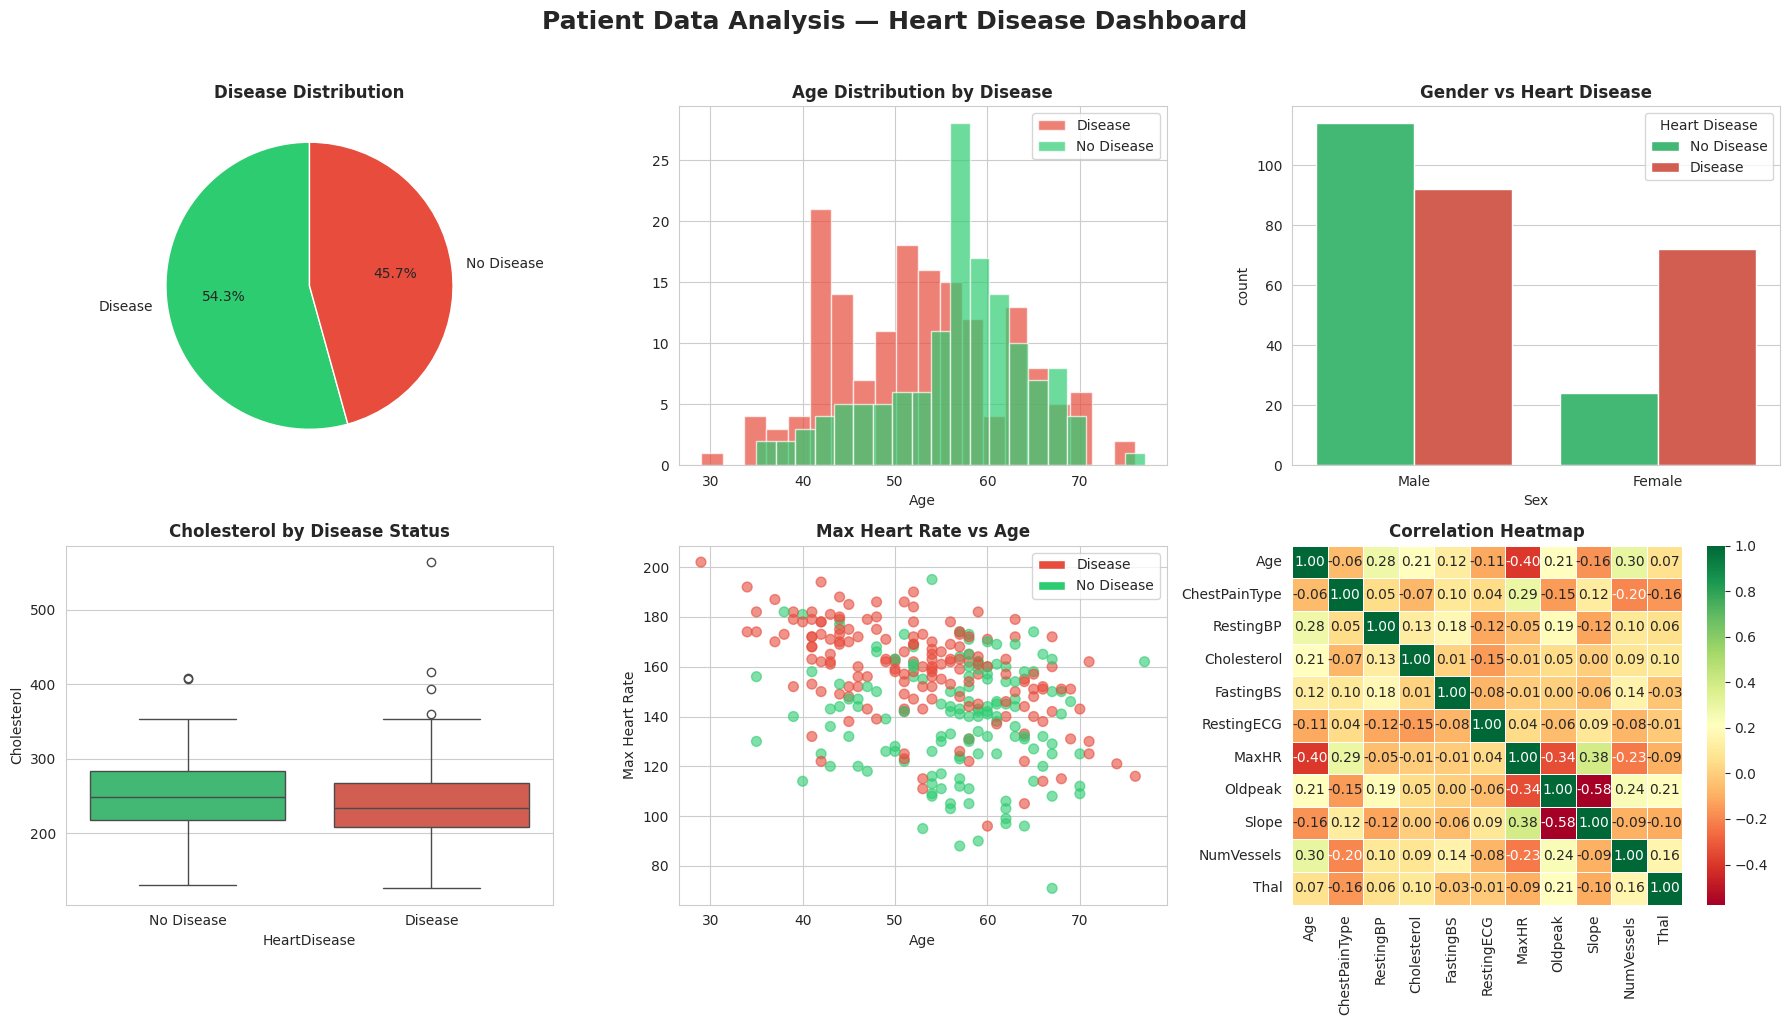

Dashboard saved to outputs/


In [7]:
sns.set_style("whitegrid")
palette = ["#2ecc71", "#e74c3c"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Patient Data Analysis — Heart Disease Dashboard",
             fontsize=18, fontweight='bold', y=1.02)

# Chart 1 — Disease Distribution
disease_counts = df['HeartDisease'].value_counts()
axes[0,0].pie(disease_counts, labels=disease_counts.index,
              autopct='%1.1f%%', colors=palette, startangle=90)
axes[0,0].set_title("Disease Distribution", fontweight='bold')

# Chart 2 — Age Distribution
df[df['HeartDisease']=='Disease']['Age'].hist(
    ax=axes[0,1], color='#e74c3c', alpha=0.7, bins=20, label='Disease')
df[df['HeartDisease']=='No Disease']['Age'].hist(
    ax=axes[0,1], color='#2ecc71', alpha=0.7, bins=20, label='No Disease')
axes[0,1].set_title("Age Distribution by Disease", fontweight='bold')
axes[0,1].set_xlabel("Age")
axes[0,1].legend()

# Chart 3 — Gender vs Disease (fixed)
sns.countplot(data=df, x='Sex', hue='HeartDisease',
              palette=palette, ax=axes[0,2])
axes[0,2].set_title("Gender vs Heart Disease", fontweight='bold')
axes[0,2].legend(title='Heart Disease')

# Chart 4 — Cholesterol Boxplot (fixed)
sns.boxplot(data=df, x='HeartDisease', y='Cholesterol',
            hue='HeartDisease', palette=palette,
            legend=False, ax=axes[1,0])
axes[1,0].set_title("Cholesterol by Disease Status", fontweight='bold')

# Chart 5 — MaxHR vs Age Scatter
colors = df['HeartDisease'].map({'Disease':'#e74c3c','No Disease':'#2ecc71'})
axes[1,1].scatter(df['Age'], df['MaxHR'], c=colors, alpha=0.6, s=50)
axes[1,1].set_title("Max Heart Rate vs Age", fontweight='bold')
axes[1,1].set_xlabel("Age")
axes[1,1].set_ylabel("Max Heart Rate")
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='Disease'),
                   Patch(facecolor='#2ecc71', label='No Disease')]
axes[1,1].legend(handles=legend_elements)

# Chart 6 — Correlation Heatmap
df_num = df.select_dtypes(include=[np.number])
sns.heatmap(df_num.corr(), annot=True, fmt=".2f",
            cmap="RdYlGn", ax=axes[1,2], linewidths=0.5)
axes[1,2].set_title("Correlation Heatmap", fontweight='bold')

plt.tight_layout()
plt.savefig("../outputs/dashboard.png", dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved to outputs/")

## Key Findings

- Approximately **54%** of patients in this dataset have heart disease
- Patients **with** heart disease tend to be slightly **older** on average
- **Male** patients show significantly higher disease prevalence than females
- Patients with heart disease show **lower maximum heart rate**
- Cholesterol alone shows **weak direct correlation** with disease presence
- Age group **40–55** has the highest concentration of disease cases

##  Data Source
[Heart Disease UCI — Kaggle](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)